# Pure Baseline Pre-Treatment Two-Stage Survival Model

### Biostatistical Rationale: Eliminating Immortal-Time & Look-Ahead Bias
In glioblastoma trials, using delivered radiotherapy dose (`dose (Gy)`, `fractions_number`) as a baseline predictor introduces severe methodological biases:
1. **Immortal-Time Bias**: Completing 30 fractions (60 Gy) takes 6 weeks. A patient must survive at least 6 weeks to receive that dose. Patients who die or rapidly deteriorate in weeks 1–2 only accumulate low doses, creating artificial reverse causation.
2. **Confounding by Indication**: Oncologists prescribe standard 60 Gy to fit, younger patients and intentionally prescribe lower doses (or palliative care) to frail, elderly patients.
3. **Look-Ahead Leakage**: At diagnosis ($t_0$ initial MRI), the final delivered radiotherapy course is an unknown future event.

### Pre-Treatment Baseline Scope ($t_0$ Landmark):
This notebook evaluates a **pure pre-treatment prognostic model** using only information known on Day 0 before radiotherapy begins:
- **Stage 1 (Clinical & Volumetric Baseline Core)**: Age, WHO Performance Status, Gender, Height, Weight, and Baseline Tumor Volume (`size_t0 (cm3)`).
- **Stage 2 (Baseline Radiomics Fine-Tuner)**: Quantitative MRI texture and heterogeneity biomarkers strictly from pre-treatment $t_0$ scans (T1gd & FLAIR).
- **Calibrated Retransformation**: Duan's smearing factor ensures log-survival predictions are properly calibrated to real survival weeks.

## 1. Environment & Imports

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import RidgeCV, ElasticNetCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
print("Libraries successfully imported.")

Libraries successfully imported.


## 2. Load Pre-Treatment Datasets (Excluding Post-Baseline Treatment Data)

We load only `clinical_data`, `rano_criteria` (for baseline tumor volume), and `pyradiomics` (baseline $t_0$). `treatment_data` is strictly excluded to prevent immortal-time bias.

In [2]:
clinical = pd.read_csv("data/CFB-GBM_clinical_data_v03_20260619.tsv", sep="\t")
rano = pd.read_csv("data/CFB-GBM_rano_criteria_v04_20260909.tsv", sep="\t")
features = pd.read_csv("data/CFB_GBM_features_extraction_pyradiomics_v03_20260619.tsv", sep="\t")

print(f"Loaded Clinical:  {clinical.shape}")
print(f"Loaded RANO:      {rano.shape}")
print(f"Loaded Radiomics: {features.shape}")
print("Note: Post-baseline treatment dataset is intentionally excluded to enforce true pre-treatment landmarking.")

Loaded Clinical:  (264, 8)
Loaded RANO:      (165, 10)
Loaded Radiomics: (2424, 150)
Note: Post-baseline treatment dataset is intentionally excluded to enforce true pre-treatment landmarking.


## 3. Pure Baseline Feature Harmonization ($t_0$ Only)

- **Target**: Column 1 of `clinical` (`"survival (weeks)"`).
- **Stage 1 Predictors**: Baseline Clinical Demographics + Baseline RANO tumor volume (`size_t0 (cm3)`).
- **Stage 2 Predictors**: Baseline $t_0$ PyRadiomics features from T1gd and FLAIR sequences.

In [3]:
target_col = clinical.columns[1]  # "survival (weeks)"
id_col = "id_patient"
print(f"Outcome target identified: '{target_col}'")

# 1. Clinical Baseline Table
df_base = clinical.copy()

# 2. Baseline Tumor Volume (RANO t0 only; discard post-treatment t1, t2)
rano_base_cols = [c for c in ["id_patient", "size_t0 (cm3)"] if c in rano.columns]
if len(rano_base_cols) > 1:
    rano_sub = rano[rano_base_cols].drop_duplicates(subset=[id_col])
    df_base = df_base.merge(rano_sub, on=id_col, how="left")

# Identify Stage 1 Pure Baseline Clinical Predictors
baseline_clinical_cols = [
    c for c in df_base.columns if c not in [id_col, target_col]
]
print(f"Stage 1 Pure Baseline Clinical Features ({len(baseline_clinical_cols)}): {baseline_clinical_cols}")

# 3. PyRadiomics Baseline (t0 only, primary sequences T1gd & FLAIR)
feat_df = features.copy()
if "Patient" in feat_df.columns:
    feat_df = feat_df.rename(columns={"Patient": id_col})
if "Temporality" in feat_df.columns:
    feat_df = feat_df[feat_df["Temporality"] == "t0"]
if "Sequence" in feat_df.columns:
    feat_df = feat_df[feat_df["Sequence"].isin(["t1gd", "flair"])]

rad_cols = [c for c in feat_df.columns if c.startswith("original_")]
if rad_cols and "Sequence" in feat_df.columns:
    feat_df[rad_cols] = feat_df[rad_cols].apply(pd.to_numeric, errors="coerce")
    rad_pivot = feat_df.pivot_table(
        index=id_col,
        columns="Sequence",
        values=rad_cols,
        aggfunc="mean"
    )
    rad_pivot.columns = [f"rad_{seq}_{col}" for col, seq in rad_pivot.columns]
    rad_pivot = rad_pivot.reset_index()
    df_master = df_base.merge(rad_pivot, on=id_col, how="left")
else:
    df_master = df_base.copy()

# Filter valid target
valid_mask = df_master[target_col].notna() & (pd.to_numeric(df_master[target_col], errors="coerce") > 0)
clean_df = df_master[valid_mask].copy()

radiomics_cols = [c for c in clean_df.columns if c.startswith("rad_")]
print(f"Harmonized baseline cohort: {len(clean_df)} patients.")
print(f"Stage 1 Clinical/Volumetric: {len(baseline_clinical_cols)} features; Stage 2 Radiomics pool: {len(radiomics_cols)} features.")

Outcome target identified: 'survival (weeks)'
Stage 1 Pure Baseline Clinical Features (7): ['age_at_t0 (years)', 'who_performance_status', 'who_guideline', 'gender', 'height (cm)', 'weight (kg)', 'size_t0 (cm3)']
Harmonized baseline cohort: 264 patients.
Stage 1 Clinical/Volumetric: 7 features; Stage 2 Radiomics pool: 214 features.


## 4. Partition and Save Holdout Test Set

An independent 15% holdout test set is partitioned and saved to disk (`test_dataset_baseline_holdout.csv`) prior to training.

In [4]:
TEST_RATIO = 0.15
RANDOM_SEED = 42

train_df, test_df = train_test_split(
    clean_df, test_size=TEST_RATIO, random_state=RANDOM_SEED
)

test_file_path = "test_dataset_baseline_holdout.csv"
test_df.to_csv(test_file_path, index=False)
print(f"Pre-treatment holdout test set ({len(test_df)} patients) saved to '{test_file_path}'")
print(f"Training partition: {len(train_df)} patients.")

# Targets in log space (log(1 + y))
y_train_raw = pd.to_numeric(train_df[target_col], errors="coerce")
y_train_log = np.log1p(y_train_raw)

X_train_clin = train_df[baseline_clinical_cols].copy()
X_train_rad = train_df[radiomics_cols].copy()

Pre-treatment holdout test set (40 patients) saved to 'test_dataset_baseline_holdout.csv'
Training partition: 224 patients.


## 5. Stage 1: Fit Pre-Treatment Clinical & Volumetric Baseline Core

We fit a lightly regularized `RidgeCV` model on pre-treatment clinical demographics and baseline tumor volume, computing **Duan's smearing factor** to calibrate log-scale predictions.

In [5]:
cat_clin_cols = X_train_clin.select_dtypes(include=["object", "category"]).columns.tolist()
num_clin_cols = X_train_clin.select_dtypes(include=["number"]).columns.tolist()

clin_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_clin_cols),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))]), cat_clin_cols)
    ]
)

stage1_pipeline = Pipeline([
    ("prep", clin_preprocessor),
    ("ridge", RidgeCV(alphas=[0.01, 0.1, 0.5, 1.0, 3.0, 10.0]))
])

stage1_pipeline.fit(X_train_clin, y_train_log)
y_train_clin_pred_log = stage1_pipeline.predict(X_train_clin)

# Calculate Stage 1 Duan's Smearing Factor
e_stage1 = y_train_log - y_train_clin_pred_log
smearing_stage1 = np.mean(np.exp(e_stage1))

y_train_clin_pred_weeks = np.maximum(0.0, smearing_stage1 * np.exp(y_train_clin_pred_log) - 1.0)
residuals_train = y_train_log - y_train_clin_pred_log

print(f"Stage 1 Pre-Treatment Ridge optimal alpha: {stage1_pipeline.named_steps['ridge'].alpha_:.4f}")
print(f"Stage 1 Train R² (log-space): {r2_score(y_train_log, y_train_clin_pred_log):.4f}")
print(f"Stage 1 Duan's Smearing Factor: {smearing_stage1:.4f}")
print(f"Stage 1 Train predictions span: {y_train_clin_pred_weeks.min():.1f} to {y_train_clin_pred_weeks.max():.1f} weeks")

Stage 1 Pre-Treatment Ridge optimal alpha: 10.0000
Stage 1 Train R² (log-space): 0.1130
Stage 1 Duan's Smearing Factor: 1.3295
Stage 1 Train predictions span: 26.6 to 119.9 weeks


## 6. Stage 2: Fit Baseline Radiomics Residual Model

We use pre-treatment $t_0$ PyRadiomics to predict the **unexplained clinical residual** ($r = y - \hat{y}_{\text{clin}}$):
1. `SelectKBest(f_regression, k=15)` pre-screens the top 15 texture biomarkers correlated with residual survival.
2. `ElasticNetCV` selects the final active non-zero imaging signatures.

In [6]:
k_screen = min(15, X_train_rad.shape[1])

rad_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("selector", SelectKBest(score_func=f_regression, k=k_screen))
])

cv_folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

stage2_pipeline = Pipeline([
    ("prep", rad_preprocessor),
    ("elastic_net", ElasticNetCV(
        l1_ratio=[0.05, 0.2, 0.5, 0.8],
        alphas=np.logspace(-4, -0.5, 50),
        cv=cv_folds,
        max_iter=10000,
        random_state=RANDOM_SEED
    ))
])

stage2_pipeline.fit(X_train_rad, residuals_train)

# Combined training predictions & Combined Smearing Factor
y_train_rad_res_pred = stage2_pipeline.predict(X_train_rad)
y_train_combined_log = y_train_clin_pred_log + y_train_rad_res_pred
e_combined = y_train_log - y_train_combined_log
smearing_combined = np.mean(np.exp(e_combined))

n_nonzero_rad = (stage2_pipeline.named_steps["elastic_net"].coef_ != 0).sum()
print(f"Stage 2 ElasticNet optimal alpha: {stage2_pipeline.named_steps['elastic_net'].alpha_:.5f}")
print(f"Active non-zero baseline radiomic biomarkers: {n_nonzero_rad} of {k_screen}")
print(f"Combined Two-Stage Smearing Factor: {smearing_combined:.4f}")

Stage 2 ElasticNet optimal alpha: 0.22758
Active non-zero baseline radiomic biomarkers: 10 of 15
Combined Two-Stage Smearing Factor: 1.2918


## 7. Post-Training Evaluation on Saved Holdout Test Set

We load `test_dataset_baseline_holdout.csv` and compare:
1. **Pre-Treatment Clinical Baseline (Stage 1)**
2. **Two-Stage Multi-Modal Baseline (Stage 1 + Stage 2 Radiomics)**

Loaded pre-treatment holdout test cohort: 40 patients.

--- Verification of Prediction Spread (Min, Median, Mean, Max) ---


,Actual Test Survival,Stage 1 Clinical Pred,Two-Stage Combined Pred
count,40.0,40.0,40.0
mean,66.9,55.6,59.6
std,45.5,12.6,22.3
min,7.0,32.8,24.8
25%,39.0,47.6,44.4
50%,55.5,53.7,53.6
75%,83.2,60.4,70.9
max,228.0,93.7,122.2



Ablation Performance on Independent Holdout Test Set:


,Stage 1: Pre-Treatment Clinical Only,Stage 1 + 2: Two-Stage Multi-Modal Baseline
R² Score,0.053,0.071
RMSE (weeks),43.676,43.255
MAE (weeks),31.560,31.669
Spearman Rank Correlation (ρ),0.327,0.217


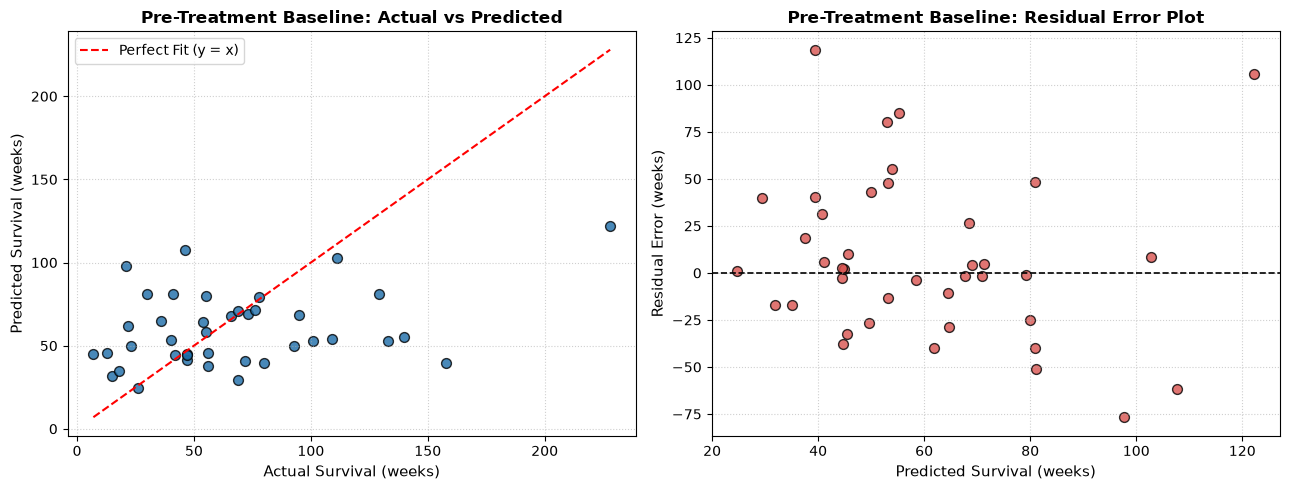

In [7]:
saved_test_df = pd.read_csv("test_dataset_baseline_holdout.csv")
print(f"Loaded pre-treatment holdout test cohort: {len(saved_test_df)} patients.")

y_test_raw = pd.to_numeric(saved_test_df[target_col], errors="coerce")
X_test_clin = saved_test_df[baseline_clinical_cols]
X_test_rad = saved_test_df[radiomics_cols]

# Stage 1 Predictions with Smearing Correction
y_test_clin_pred_log = stage1_pipeline.predict(X_test_clin)
y_test_clin_pred = np.maximum(0.0, smearing_stage1 * np.exp(y_test_clin_pred_log) - 1.0)

# Stage 2 Residual Predictions
y_test_rad_res_pred = stage2_pipeline.predict(X_test_rad)

# Combined Multi-Modal Predictions with Smearing Correction
y_test_combined_pred_log = y_test_clin_pred_log + y_test_rad_res_pred
y_test_combined_pred = np.maximum(0.0, smearing_combined * np.exp(y_test_combined_pred_log) - 1.0)

# Check Prediction Distribution & Spread
spread_df = pd.DataFrame({
    "Actual Test Survival": y_test_raw.describe(),
    "Stage 1 Clinical Pred": pd.Series(y_test_clin_pred).describe(),
    "Two-Stage Combined Pred": pd.Series(y_test_combined_pred).describe()
})
print("\n--- Verification of Prediction Spread (Min, Median, Mean, Max) ---")
display(spread_df.round(1))

# Metrics
def calc_metrics(y_true, y_pred):
    return [
        r2_score(y_true, y_pred),
        np.sqrt(mean_squared_error(y_true, y_pred)),
        mean_absolute_error(y_true, y_pred),
        spearmanr(y_true, y_pred)[0]
    ]

metrics_comparison = pd.DataFrame({
    "Stage 1: Pre-Treatment Clinical Only": calc_metrics(y_test_raw, y_test_clin_pred),
    "Stage 1 + 2: Two-Stage Multi-Modal Baseline": calc_metrics(y_test_raw, y_test_combined_pred)
}, index=["R² Score", "RMSE (weeks)", "MAE (weeks)", "Spearman Rank Correlation (ρ)"])

print("\nAblation Performance on Independent Holdout Test Set:")
display(metrics_comparison.round(3))

# Diagnostic Plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Actual vs Combined Predicted
axes[0].scatter(y_test_raw, y_test_combined_pred, color="#1b6ca8", edgecolors="k", s=50, alpha=0.8)
lims = [min(y_test_raw.min(), y_test_combined_pred.min()), max(y_test_raw.max(), y_test_combined_pred.max())]
axes[0].plot(lims, lims, "r--", lw=1.5, label="Perfect Fit (y = x)")
axes[0].set_xlabel("Actual Survival (weeks)", fontsize=11)
axes[0].set_ylabel("Predicted Survival (weeks)", fontsize=11)
axes[0].set_title("Pre-Treatment Baseline: Actual vs Predicted", fontsize=12, fontweight="bold")
axes[0].legend()
axes[0].grid(True, linestyle=":", alpha=0.6)

# Plot 2: Residuals vs Predicted
residuals_combined = y_test_raw - y_test_combined_pred
axes[1].scatter(y_test_combined_pred, residuals_combined, color="#d9534f", edgecolors="k", s=50, alpha=0.8)
axes[1].axhline(0, color="black", linestyle="--", lw=1.2)
axes[1].set_xlabel("Predicted Survival (weeks)", fontsize=11)
axes[1].set_ylabel("Residual Error (weeks)", fontsize=11)
axes[1].set_title("Pre-Treatment Baseline: Residual Error Plot", fontsize=12, fontweight="bold")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 8. Selected Pre-Treatment Radiomic Biomarkers

In [ ]:
selector = stage2_pipeline.named_steps["prep"].named_steps["selector"]
support = selector.get_support()
selected_rad_names = np.array(radiomics_cols)[support]
en_coefs = stage2_pipeline.named_steps["elastic_net"].coef_

rad_coef_df = pd.DataFrame({
    "Feature": selected_rad_names,
    "Residual_Coefficient": en_coefs,
    "Abs_Coefficient": np.abs(en_coefs)
}).sort_values("Abs_Coefficient", ascending=False)

non_zero_rad = rad_coef_df[rad_coef_df["Residual_Coefficient"] != 0].copy()
print(f"Selected Non-zero Pre-Treatment Biomarkers: {len(non_zero_rad)} out of {len(selected_rad_names)} screened.")
display(non_zero_rad.round(4))

if not non_zero_rad.empty:
    plot_df = non_zero_rad.head(10).sort_values("Residual_Coefficient", ascending=True)
    colors = ["#1b6ca8" if c > 0 else "#d9534f" for c in plot_df["Residual_Coefficient"]]
    plt.figure(figsize=(10, 5))
    plt.barh(plot_df["Feature"], plot_df["Residual_Coefficient"], color=colors, edgecolor="black")
    plt.axvline(0, color="black", linewidth=0.8)
    plt.title("Top Pre-Treatment Radiomics Biomarkers Explaining Residual Survival", fontsize=12, fontweight="bold")
    plt.xlabel("ElasticNet Coefficient (Impact on Log Residual Survival)", fontsize=11)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()